# Day 1 — A wall as a belief, and where to look next

**The challenge, stage 0.** Before the robot can estimate a room, it must be able to hold a belief
about one wall. Today you will:

1. fit a wall to a LiDAR scan as a **Laplace belief**, a Gaussian whose covariance is the inverse
   curvature of the free energy;
2. check whether that covariance is *honest*, and fix it when it is not;
3. use the **free energy** to choose between two models of the same wall;
4. choose the robot's **next viewpoint** by the information it is expected to buy, in nats, and
   then pay for travel with the same currency.

Today the robot knows its own pose exactly, and we cheat on *which* LiDAR points belong to the
wall. Day 2 removes both cheats.

In [1]:
import sys
from pathlib import Path

LABS = Path.cwd() if (Path.cwd() / "toyworld").exists() else Path.cwd().parent
sys.path.insert(0, str(LABS))

import matplotlib.pyplot as plt
import numpy as np

from toyworld import Gaussian, Lidar, draw, info_gain, laplace, se2, two_room_apartment
from toyworld.geometry import point_segment_distance

rng = np.random.default_rng(0)
world = two_room_apartment()

## 0. Meet the world

Two rooms, a door, a table, a bottle and a chair. The sensor today is a forward-looking LiDAR
with a 90° field of view: 90 beams, 2 cm of independent range noise per beam.

what the beams hit: {np.str_('wall'): 65, np.str_('table'): 25}


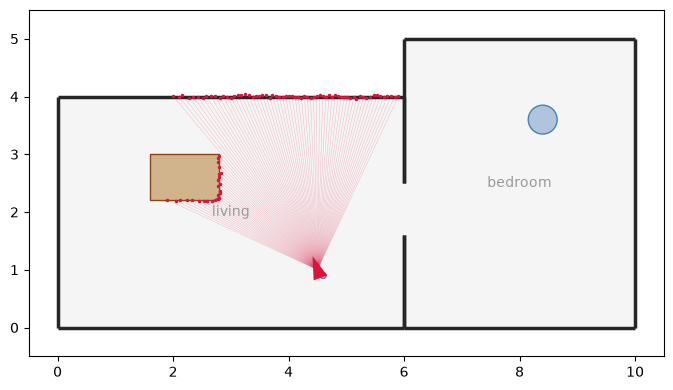

In [2]:
lidar = Lidar(n_beams=90, fov=np.deg2rad(90), sigma=0.02)
pose0 = np.array([4.5, 1.0, np.deg2rad(110)])   # the robot's (known) pose today
scan0 = lidar.scan(world, pose0, rng)

fig, ax = plt.subplots(figsize=(9, 4.5))
draw.world(world, ax)
draw.scan(scan0, ax=ax, rays=True)
draw.robot(pose0, ax)
ax.set_xlim(-0.5, 10.5); ax.set_ylim(-0.5, 5.5)
print("what the beams hit:", {l: int((scan0.labels == l).sum()) for l in set(scan0.labels)})

The robot receives only `scan.points()`: hit points in its own sensor frame. Everything with
`true_` in its name, and `scan.labels`, is ground truth, kept for grading. The cell below is
today's cheat: it uses the true labels and the true wall geometry to pick out the points on the
living room's north wall.

In [3]:
NORTH = np.array([[[0.0, 4.0], [6.0, 4.0]]])   # the living room's north wall, as a segment


def wall_points(scan, wall=NORTH, tol=0.15):
    """World-frame hit points on `wall`, and the world bearing of each beam. (Uses ground truth!)"""
    pts = se2.transform_points(scan.pose, scan.points())
    bearings = scan.pose[2] + scan.angles[scan.hit]
    on_wall = (scan.labels[scan.hit] == "wall") & (point_segment_distance(pts, wall)[:, 0] < tol)
    return pts[on_wall], bearings[on_wall]


pts0, bear0 = wall_points(scan0)
print(f"{len(pts0)} points on the north wall, spanning x = {pts0[:, 0].min():.2f} .. {pts0[:, 0].max():.2f} m")

65 points on the north wall, spanning x = 2.00 .. 5.90 m


## 1. A wall as a Laplace belief

Model the wall as an infinite line with unit normal $n(\alpha) = (\cos\alpha, \sin\alpha)$ at
distance $d$ from the origin. A point $p$ lies on it when $n(\alpha)^\top p = d$, so the
residual of point $i$ is

$$ r_i(\alpha, d) = \cos\alpha\, x_i + \sin\alpha\, y_i - d, \qquad
   r_i \sim \mathcal N(0, \sigma^2). $$

**Exercise 1.** Write the residual and its Jacobian $\partial r_i / \partial(\alpha, d)$.
(Check yourself: the row for point $i$ should be $[\,-\sin\alpha\, x_i + \cos\alpha\, y_i,\; -1\,]$.)

In [4]:
def residual(pts):
    def r(theta):
        alpha, d = theta
        return np.cos(alpha) * pts[:, 0] + np.sin(alpha) * pts[:, 1] - d
    return r


def jacobian(pts):
    def J(theta):
        alpha, d = theta
        return np.stack([-np.sin(alpha) * pts[:, 0] + np.cos(alpha) * pts[:, 1], -np.ones(len(pts))], axis=1)
    return J

**Exercise 2.** Fit the wall with `laplace(residual, x0, sigma, jacobian=...)`. It runs
Gauss–Newton to the mode, and returns the belief $\mathcal N(\mu, H^{-1})$ together with the
Laplace free energy. Start from a deliberately wrong guess, $\alpha_0 = 100°$ and
$d_0 = 3.5$ m. Then draw 30 lines sampled from the belief.

alpha = 89.877° ± 0.130°,  d = 4.0100 ± 0.0096 m
correlation(alpha, d) = -0.97;  Gauss-Newton iterations: 5


Text(0.5, 1.0, 'belief samples (sd ×10)')

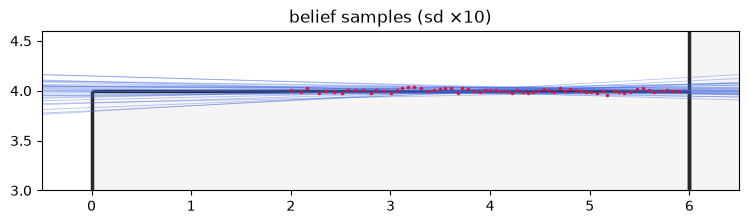

In [5]:
fit0 = laplace(residual(pts0), [np.deg2rad(100), 3.5], 0.02, jacobian=jacobian(pts0))
wall0 = fit0.belief
print(f"alpha = {np.degrees(wall0.mu[0]):.3f}° ± {np.degrees(wall0.sd[0]):.3f}°,  d = {wall0.mu[1]:.4f} ± {wall0.sd[1]:.4f} m")
print(f"correlation(alpha, d) = {wall0.Sigma[0, 1] / np.prod(wall0.sd):+.2f};  Gauss-Newton iterations: {fit0.iterations}")


def draw_wall_belief(belief, ax, n=30, color="royalblue", x=np.array([-0.5, 6.5])):
    for a, d in belief.sample(n, rng):
        ax.plot(x, (d - np.cos(a) * x) / np.sin(a), color=color, lw=0.6, alpha=0.4)


fig, ax = plt.subplots(figsize=(9, 3))
draw.world(world, ax, things=False)
draw_wall_belief(Gaussian(wall0.mu, wall0.Sigma * 100), ax)   # ×10 in sd, so you can see it
ax.plot(pts0[:, 0], pts0[:, 1], ".", color="crimson", ms=3)
ax.set_xlim(-0.5, 6.5); ax.set_ylim(3.0, 4.6); ax.set_title("belief samples (sd ×10)")

**Question.** Why are $\alpha$ and $d$ correlated, and what sets the sign? (Hint: where is the
origin relative to the points? Move the origin to the centre of the points and the correlation
should disappear.)

*Answer.* $d$ is a distance from the **origin**, and the points sit at $x \approx 2$–$6$ m.
Rotating the line about the centroid of the points changes its distance to the origin, so the
data cannot pin $\alpha$ without moving $d$ with it. The Jacobian column for $\alpha$ is the lever
arm $-\sin\alpha\,x_i + \cos\alpha\,y_i \approx -x_i$. Centre the parameterisation on the
centroid and the information matrix becomes diagonal.

## 2. Is the covariance honest?

$\Sigma = H^{-1}$ is a **claim** about how far the fit would wander if you scanned again. Test the
claim: scan 500 times from the same pose, fit each scan, and compare the spread of the fits with
the predicted $\sigma$.

**Exercise 3.** Fill in the loop.

In [6]:
def monte_carlo(sigma_fn, n=500):
    fits, sigmas = [], []
    for _ in range(n):
        s = lidar.scan(world, pose0, rng)
        p, b = wall_points(s)
        res = laplace(residual(p), [np.pi / 2, 4.0], sigma_fn(p, b), jacobian=jacobian(p))
        fits.append(res.belief.mu)
        sigmas.append(res.belief.sd)
    return np.std(fits, axis=0), np.mean(sigmas, axis=0)


emp, pred = monte_carlo(lambda p, b: 0.02)
print("uniform sigma:   empirical sd", emp.round(5), "  predicted sd", pred.round(5), "  ratio", (pred / emp).round(3))

uniform sigma:   empirical sd [0.00207 0.00846]   predicted sd [0.00228 0.00958]   ratio [1.099 1.133]


The prediction is about 10% **too pessimistic**. That is not Monte Carlo noise; re-run it and the
gap stays. Something in the likelihood is wrong.

**Exercise 4.** The LiDAR's noise is along the **beam**, but the residual measures distance along
the wall's **normal**. A range error $\epsilon$ on a beam with direction $u$ moves the point by
$\epsilon\,(u^\top n)$ off the wall. So the residual's standard deviation is
$\sigma_i = \sigma\,|u_i^\top n|$, not $\sigma$. Write that per-point sigma and re-run the test.

In [7]:
def incidence_sigma(p, bearings, alpha=np.pi / 2):
    u = np.stack([np.cos(bearings), np.sin(bearings)], axis=1)
    n = np.array([np.cos(alpha), np.sin(alpha)])
    return 0.02 * np.abs(u @ n)


emp, pred = monte_carlo(incidence_sigma)
print("incidence sigma: empirical sd", emp.round(5), "  predicted sd", pred.round(5), "  ratio", (pred / emp).round(3))

incidence sigma: empirical sd [0.00192 0.00812]   predicted sd [0.00202 0.00829]   ratio [1.051 1.021]


**Lesson.** A Laplace covariance is exactly as honest as the likelihood you wrote. Here the wrong
likelihood made the belief *under*-confident. That costs little. Day 2 has a wrong likelihood
that makes it badly *over*-confident, which costs a great deal. The real robot's localiser
weights each LiDAR return by the incidence $|\hat r^\top \hat n|$ for exactly this reason.

From here on, fit walls with `incidence_sigma`.

In [8]:
fit0 = laplace(residual(pts0), [np.pi / 2, 4.0], incidence_sigma(pts0, bear0), jacobian=jacobian(pts0))
wall0 = fit0.belief

## 3. Free energy as the price of a model

Rooms are mostly rectilinear. A **Manhattan** model of this wall fixes $\alpha = 90°$ and has a
single parameter, $d$. The **free** model keeps both parameters, with a prior
$\alpha \sim \mathcal N(90°, s^2)$. Both models fit the data equally well, so which does the free
energy prefer, and by how much?

The Laplace free energy approximates the surprise $-\ln p(o \mid \text{model})$. Lower is better,
and the difference is a log Bayes factor in nats.

**Exercise 5.** Compute $\Delta F = F_\text{free} - F_\text{Manhattan}$ for prior widths
$s$ from 0.1° to 30°. Use the prior $d \sim \mathcal N(3, 2^2)$ in both models.

Text(0.5, 1.0, 'the complexity price of a free parameter')

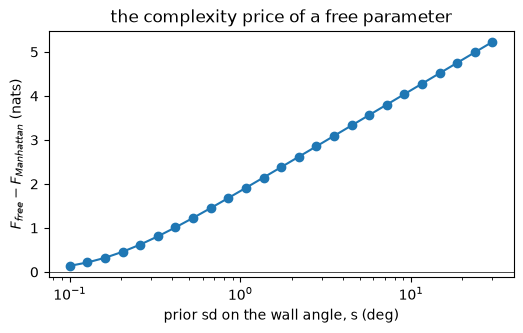

In [9]:
sig0 = incidence_sigma(pts0, bear0)
manhattan = laplace(lambda th: residual(pts0)(np.array([np.pi / 2, th[0]])), [3.0], sig0,
                    prior=Gaussian([3.0], [[4.0]]))
widths = np.deg2rad(np.logspace(-1, np.log10(30), 25))
dF = []
for s in widths:
    free = laplace(residual(pts0), [np.pi / 2, 3.0], sig0, jacobian=jacobian(pts0),
                   prior=Gaussian([np.pi / 2, 3.0], np.diag([s ** 2, 4.0])))
    dF.append(free.free_energy - manhattan.free_energy)

plt.figure(figsize=(6, 3.2))
plt.semilogx(np.degrees(widths), dF, "o-")
plt.axhline(0, color="k", lw=0.5)
plt.xlabel("prior sd on the wall angle, s (deg)"); plt.ylabel(r"$F_{free} - F_{Manhattan}$ (nats)")
plt.title("the complexity price of a free parameter")

Above zero, the Manhattan model wins. The penalty grows like $\ln(s/\sigma_\alpha)$: it is the
complexity term, $\mathrm{KL}[q\,\|\,p]$, charging for how much the prior had to be squeezed to
reach the posterior.

**Exercise 6.** Is the Manhattan model therefore always right? Rotate the points by 1.5° about
their centroid, which is what a slightly skew wall would look like, and compare again at
$s = 5°$.

In [10]:
c = pts0.mean(axis=0)
tilted = (pts0 - c) @ se2.rot(np.deg2rad(1.5)).T + c
m_t = laplace(lambda th: residual(tilted)(np.array([np.pi / 2, th[0]])), [3.0], sig0, prior=Gaussian([3.0], [[4.0]]))
f_t = laplace(residual(tilted), [np.pi / 2, 3.0], sig0, jacobian=jacobian(tilted),
              prior=Gaussian([np.pi / 2, 3.0], np.diag([np.deg2rad(5) ** 2, 4.0])))
print(f"tilted wall: F_free - F_Manhattan = {f_t.free_energy - m_t.free_energy:+.1f} nats")

tilted wall: F_free - F_Manhattan = -70.2 nats


**Lesson.** Nobody wrote "if the angle error exceeds k degrees, abandon Manhattan". The
accuracy term grew until it outweighed the complexity term. That is the course's first instance
of **no thresholds**: the decision falls out of comparing two free energies.

## 4. Where to look next

At decision time the current scan has already happened, so $\partial F / \partial a = 0$.
Actions are scored by the free energy they are *expected* to produce. For a Gaussian belief and
a linear-Gaussian measurement, the epistemic part of the expected free energy is the expected
entropy drop, which equals the mutual information, which equals the D-optimal design criterion:

$$ \Delta H(v) = \tfrac12 \ln\frac{|\Lambda + J_v^\top R_v^{-1} J_v|}{|\Lambda|}. $$

`info_gain(Lambda, J, R)` computes this. To predict *which* points a viewpoint $v$ would see we
cheat once more: we ray-cast the true world (with zero noise). On Day 5 the robot will have to
predict that from its own beliefs.

**Exercise 7.** Compute $\Delta H$ for each candidate below and rank them. Before running, guess
which wins.

stay here       sees  65 wall points   ΔH = 0.693 nats   distance 0.00 m
under the wall  sees  90 wall points   ΔH = 0.705 nats   distance 2.75 m
far west        sees  39 wall points   ΔH = 0.949 nats   distance 3.70 m
behind table    sees  14 wall points   ΔH = 0.543 nats   distance 2.33 m
east corner     sees  47 wall points   ΔH = 0.587 nats   distance 1.12 m


(-0.3, 4.4)

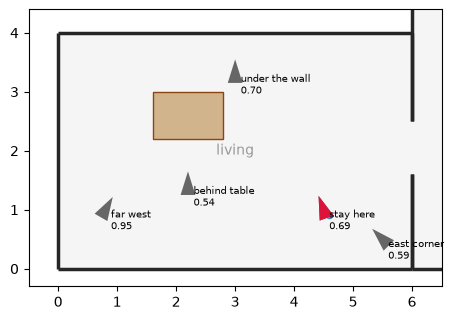

In [11]:
candidates = {
    "stay here":     [4.5, 1.0, np.deg2rad(110)],
    "under the wall": [3.0, 3.3, np.deg2rad(90)],
    "far west":      [0.8, 1.0, np.deg2rad(60)],
    "behind table":  [2.2, 1.4, np.deg2rad(90)],
    "east corner":   [5.5, 0.5, np.deg2rad(135)],
}
oracle = Lidar(n_beams=90, fov=np.deg2rad(90), sigma=0.0)


def predicted_gain(belief, view):
    s = oracle.scan(world, np.asarray(view), rng)
    p, b = wall_points(s)
    if len(p) == 0:
        return 0.0, 0
    J = jacobian(p)(belief.mu)
    R = np.diag(incidence_sigma(p, b, belief.mu[0]) ** 2)
    return info_gain(belief.precision, J, R), len(p)


fig, ax = plt.subplots(figsize=(9, 3.6))
draw.world(world, ax)
for name, v in candidates.items():
    g, n = predicted_gain(wall0, v)
    print(f"{name:15s} sees {n:3d} wall points   ΔH = {g:.3f} nats   distance {np.hypot(v[0] - pose0[0], v[1] - pose0[1]):.2f} m")
    draw.robot(v, ax, color="0.4"); ax.annotate(f"{name}\n{g:.2f}", v[:2], fontsize=7, xytext=(4, -14), textcoords="offset points")
draw.robot(pose0, ax); ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.3, 4.4)

**Questions.**
- "Stay here" gains almost exactly $\ln 2 = 0.693$ nats. Why that number?
- "Far west" sees *fewer* points than "under the wall" but gains more. Why?

*Answers.*
- A second identical scan doubles the information matrix: $|2\Lambda| / |\Lambda| = 2^2$ for a
  two-parameter belief, so $\Delta H = \tfrac12 \ln 4 = \ln 2$.
- The first scan saw the east part of the wall ($x \gtrsim 2$). The west end adds **lever arm**
  on the angle: points far from those already seen constrain $\alpha$ in a direction the current
  information matrix is weak in. Information depends on where the new data sit relative to what
  is already known, not on how many points there are.

**Exercise 8 — diminishing returns.** If the robot stays and scans again and again, what is the
$k$-th look worth? Compute it with `info_gain` and compare with $\ln\frac{k+1}{k}$.

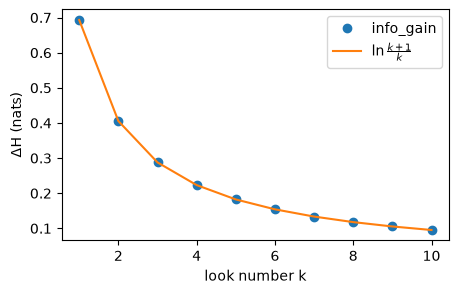

In [12]:
s = oracle.scan(world, pose0, rng)
p, b = wall_points(s)
J1 = jacobian(p)(wall0.mu)
R1 = np.diag(incidence_sigma(p, b) ** 2)
L1 = J1.T @ np.linalg.solve(R1, J1)   # the information in one look
ks = np.arange(1, 11)
gains = [info_gain(k * L1, J1, R1) for k in ks]
plt.figure(figsize=(5, 3))
plt.plot(ks, gains, "o", label="info_gain")
plt.plot(ks, np.log((ks + 1) / ks), "-", label=r"$\ln\frac{k+1}{k}$")
plt.xlabel("look number k"); plt.ylabel("ΔH (nats)"); plt.legend()

## 5. Paying for travel in the same currency

The expected free energy has a **pragmatic** term too. The simplest one is a preference for not
driving far: $G(v) = \beta\,\lVert v - x\rVert - \Delta H(v)$, with $\beta$ in nats per metre.

**Exercise 9.** For $\beta \in [0, 0.2]$ nats/m, which candidate minimises $G$? Find the $\beta$
at which the robot stops moving and simply scans again.

In [13]:
gains = {name: predicted_gain(wall0, v)[0] for name, v in candidates.items()}
dists = {name: np.hypot(v[0] - pose0[0], v[1] - pose0[1]) for name, v in candidates.items()}
for beta in np.linspace(0, 0.2, 21):
    G = {name: beta * dists[name] - gains[name] for name in candidates}
    best = min(G, key=G.get)
    print(f"beta = {beta:.2f} nats/m  ->  {best}")

beta = 0.00 nats/m  ->  far west
beta = 0.01 nats/m  ->  far west
beta = 0.02 nats/m  ->  far west
beta = 0.03 nats/m  ->  far west
beta = 0.04 nats/m  ->  far west
beta = 0.05 nats/m  ->  far west
beta = 0.06 nats/m  ->  far west
beta = 0.07 nats/m  ->  stay here
beta = 0.08 nats/m  ->  stay here
beta = 0.09 nats/m  ->  stay here
beta = 0.10 nats/m  ->  stay here
beta = 0.11 nats/m  ->  stay here
beta = 0.12 nats/m  ->  stay here
beta = 0.13 nats/m  ->  stay here
beta = 0.14 nats/m  ->  stay here
beta = 0.15 nats/m  ->  stay here
beta = 0.16 nats/m  ->  stay here
beta = 0.17 nats/m  ->  stay here
beta = 0.18 nats/m  ->  stay here
beta = 0.19 nats/m  ->  stay here
beta = 0.20 nats/m  ->  stay here


**Question — the most important one today.** For any $\beta$ above about 0.07, the robot prefers to
stay and re-scan, because a repeat look is "worth" $\ln 2$ nats for free. What does the model
*assume* that makes the repeat look so valuable? Would that assumption hold on a real robot?

*Answer.* The value $\ln 2$ assumes the second scan's errors are **independent** of the first's.
On a real robot, both scans share the same pose error, the same sensor-mount error and the same
calibration error. Those common-mode errors do not average away, so the second look is worth far
less than $\ln 2$. Averaging removes independent error, not shared error. Day 2 puts a number on
this (the common-mode ceiling). The robot's real layout explorer takes the opposite extreme: its
map keeps one point per voxel, so a repeat look adds nothing at all, and its "precision" term
turned out to be inert. What carries that explorer is credit for what a viewpoint can *resolve*,
not for how often it has been seen (post-thesis result, work in progress).

## 6. Go there and look

**Exercise 10.** Move to "far west", scan, and update the belief. The update is another Laplace
fit, with the current belief as the **prior**. Compare the realised entropy drop with the
prediction.

In [14]:
view = np.asarray(candidates["far west"])
s = lidar.scan(world, view, rng)
p, b = wall_points(s)
fit1 = laplace(residual(p), wall0.mu, incidence_sigma(p, b, wall0.mu[0]), jacobian=jacobian(p), prior=wall0)
wall1 = fit1.belief
print(f"predicted ΔH = {gains['far west']:.3f} nats,  realised ΔH = {wall0.entropy() - wall1.entropy():.3f} nats")
print(f"alpha sd: {np.degrees(wall0.sd[0]):.4f}° -> {np.degrees(wall1.sd[0]):.4f}°")

predicted ΔH = 0.949 nats,  realised ΔH = 0.950 nats
alpha sd: 0.1155° -> 0.0569°


Prediction and realisation agree because the problem is close to linear. Note *what* agreed:
the entropy drop of a Gaussian depends on **where** you look, not on **what** you see, so it can
be computed before the robot moves. That is what makes an expected free energy computable.

## Take-aways
- A belief is a mean **and** a covariance. The covariance is the curvature of the free energy,
  and it is only as honest as the likelihood.
- Model choice is free-energy comparison: complexity against accuracy, in nats, with no
  threshold.
- Where to look is information gain, in the same nats, so travel can be priced against it with a
  single exchange rate.
- Tomorrow the robot loses its known pose and its labelled points. The wall becomes four walls,
  the pose becomes one more belief, and the walls and the pose must be estimated *together*.